# XXZ model on the kagome lattice with ClusterCPS

We solve the XXZ model on the kagome lattice
$$
H \;=\; J_{xy}\sum_{\langle ij\rangle}\left(S^x_iS^x_j + S^y_iS^y_j\right) \;+\; J_z\sum_{\langle ij\rangle} S^z_iS^z_j ,
\qquad S = \sigma/2 ,
$$

with $J_z = 1$ and $J_{xy} = -0.5$. We use a `ClusterCPS` built on 12-site star-of-David clusters as the guiding wavefunction.

In [1]:
import os
os.environ["NETKET_NO_TIPS"] = "1"   # silence NetKet's tips
import numpy as np
import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt
from matplotlib.patches import Polygon

from pygfmc import run, evaluate_observables
from pygfmc.walkers import prepare_walkers_sz
from pygfmc.hamiltonian import SpinHalf, kagome, exact_diagonalization
from pygfmc.wavefunction import ClusterCPS, train_with_netket
import netket as nk          # after pygfmc, so that everything stays in float32

print(f'JAX version : {jax.__version__}')
print(f'Backend     : {jax.default_backend()}')

JAX version : 0.9.2
Backend     : cpu


## 1. Lattice and clusters

`kagome(Lx, Ly)` returns a periodic kagome lattice with $L_x \times L_y$ unit cells of three sites. We use a
$3\times2$ lattice ($N=18$), which remains small enough for exact diagonalization, and a $6\times6$ lattice ($N=108$). 


In [2]:
lat18  = kagome(3, 2)   # N = 18, small enough for exact diagonalization
lat108 = kagome(6, 6)   # N = 108

h18  = SpinHalf.create(lat18.edges,  J_x=-0.5, J_y=-0.5, J_z=1.)
h108 = SpinHalf.create(lat108.edges, J_x=-0.5, J_y=-0.5, J_z=1.)

E0 = float(exact_diagonalization(h18, number_of_states=1)[0][0])   # exact ground state of the small lattice
print(f'ED, N = 18: E0/N = {E0 / h18.N:.7f}')

ED, N = 18: E0/N = -0.3995310


## 2. Guiding wavefunction

`ClusterCPS` assigns one amplitude to each spin pattern on a **star of David**.


The amplitude of a configuration $x$ is the product over all stars $s$ on the lattice (the number of stars is $N/3$):

$$\psi_T(x) = \prod_{s} \Phi(x_s)\,.$$

$\Phi$ is a lookup table that maps a spin configuration $x_s$ of a star $s$ (12 spins per star) to a real number. There are $2^{12}=4096$ amplitudes in total. 

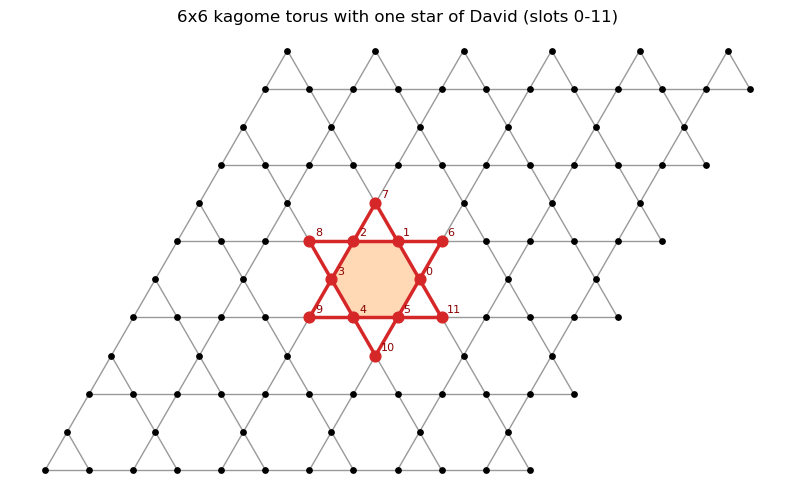

In [3]:
def stars(lat):
    # star of David: the 6 hexagon sites (slots 0-5), then the tip of the triangle on each
    # hexagon edge (k, k+1) (slots 6-11), i.e. the common neighbor of the two hexagon sites
    nbrs = [set() for _ in range(lat.N)]
    for i, j in lat.edges:
        nbrs[i].add(j); nbrs[j].add(i)
    return np.array([list(h) + [(nbrs[h[k]] & nbrs[h[(k + 1) % 6]] - set(h)).pop() for k in range(6)]
                     for h in lat.extras['hexagons']])


stars18, stars108 = stars(lat18), stars(lat108)
pos = lat108.extras['positions']
s = stars108[np.argmin(np.linalg.norm(lat108.extras['hexagon_centers'] - pos.mean(axis=0), axis=1))]

fig, ax = plt.subplots(figsize=(10, 7))
for i, j in lat108.edges:
    if np.linalg.norm(pos[i] - pos[j]) < 1.01:            # skip bonds through the periodic boundary
        color, lw = ('tab:red', 2.5) if i in s and j in s else ('0.6', 1)
        ax.plot(*pos[[i, j]].T, color=color, lw=lw)
ax.add_patch(Polygon(pos[s[:6]], closed=True, fc='tab:orange', alpha=0.3))
ax.scatter(*pos.T, s=15, c='k', zorder=3)
ax.scatter(*pos[s].T, s=60, c='tab:red', zorder=4)
for slot, i in enumerate(s):
    ax.annotate(str(slot), pos[i], xytext=(4, 4), textcoords='offset points', fontsize=8, color='darkred')
ax.set_aspect('equal'); ax.axis('off'); ax.set_title('6x6 kagome torus with one star of David (slots 0-11)')
plt.show()

We employ spatial and spin symmetries to reduce the number of free parameters.

The star of David has 12 automorphisms ($D_6$). Including the time-reversal symmetry (global spin flip $x\to-x$), we have 24 symmetry operations. 

With these symmetries the table has 210 entries instead of 4096. These 210 numbers are the full variational
state.

In [4]:
rot = np.array([1, 2, 3, 4, 5, 0, 7, 8, 9, 10, 11, 6])     # C6: slot -> image slot
mir = np.array([0, 5, 4, 3, 2, 1, 11, 10, 9, 8, 7, 6])      # mirror
D6 = []
for r in range(6):
    p = np.arange(12)
    for _ in range(r):
        p = rot[p]
    D6 += [p, mir[p]]
D6 = np.array(D6)

n_params = ClusterCPS([dict(clusters=stars18, symmetries=D6, parity=True)]).n_params
print(f'independent table entries: {n_params} (of 2^12 = {2**12})')

independent table entries: 210 (of 2^12 = 4096)


## 3. Training the guide with NetKet

We train the table with NetKet on the $N = 18$ lattice; it is trained again on $N = 108$ below.

In [5]:
guide18 = ClusterCPS([dict(clusters=stars18, symmetries=D6, parity=True)])   # uniform start
guide18, hist18 = train_with_netket(
    h18, guide18, n_iter=150, learning_rate=0.05, n_samples=1024,
    sr=True, qgt=nk.optimizer.qgt.QGTJacobianDense, diag_shift=1e-2, seed=0, return_history=True)
E_vmc18 = float(np.mean(hist18[-20:]))
print(f'VMC E/N = {E_vmc18 / h18.N:.6f} (mean of last 20 iterations),  ED E0/N = {E0 / h18.N:.6f}')

VMC E/N = -0.399487 (mean of last 20 iterations),  ED E0/N = -0.399531


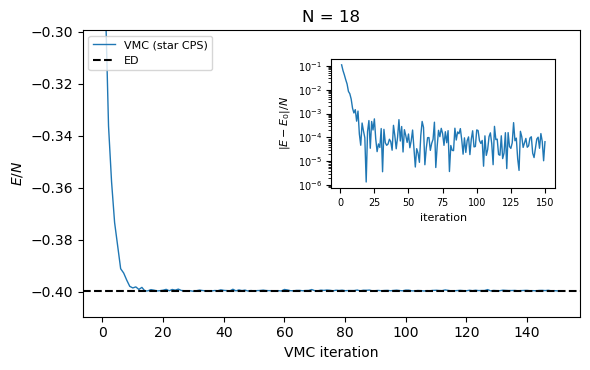

In [6]:
fig, ax = plt.subplots(figsize=(6, 3.8))
ax.plot(np.arange(1, len(hist18) + 1), hist18 / h18.N, lw=1, label='VMC (star CPS)')
ax.axhline(E0 / h18.N, color='k', ls='--', label='ED')
ax.set_ylim(E0 / h18.N - 0.01, E0 / h18.N + 0.1)
ax.set_xlabel('VMC iteration'); ax.set_ylabel('$E/N$'); ax.legend(loc='upper left', fontsize=8); ax.set_title(f'N = {h18.N}')

ins = ax.inset_axes([0.5, 0.45, 0.45, 0.45])           # inset: |E_VMC - E0| / N on a log scale
ins.semilogy(np.arange(1, len(hist18) + 1), np.abs(hist18 - E0) / h18.N, lw=1)
ins.set_xlabel('iteration', fontsize=8); ins.set_ylabel(r'$|E - E_0|/N$', fontsize=8)
ins.tick_params(labelsize=7)
plt.tight_layout(); plt.show()

The variational ansatz closely approximates the ground state.

## 4. Saving and loading the guide

The trained guide is written to `kagome_guide.h5` and read back. This supports independent GFMC calculations with the same guide.

In [7]:
GUIDE_FILE = 'kagome_guide.h5'
guide18.save(GUIDE_FILE, J_z=1.0, J_xy=-0.5, N=h18.N)
loaded18 = ClusterCPS.load(GUIDE_FILE)

test_cfgs = prepare_walkers_sz(8, h18.N, jax.random.PRNGKey(123), sz=0).config
assert np.array_equal(np.asarray(guide18.log_psi(test_cfgs)), np.asarray(loaded18.log_psi(test_cfgs)))
print('loaded guide reproduces the trained one')

loaded guide reproduces the trained one


## 5. GFMC on $N=18$ with and without the guide

We use the continuous-time propagation with `step_size = 0.2`, so the window $p$ corresponds to the projection
time $\tau=p\beta/2$. The walkers start from random configurations with $S^z_\mathrm{tot}=0$ and are equilibrated
for 1000 steps. Error bars come from a blocked jackknife.

In [8]:
def gfmc(h, guide, n_steps, seed, verbosity=7, number_of_outputs=10):
    walkers = prepare_walkers_sz(512, h.N, jax.random.PRNGKey(seed), sz=0)
    walkers, energy, obs, stats, raw = run(
        walkers, n_steps, h, step_size=0.2, guide=guide, p_array=[2, 8, 16, 32, 64],
        rng_key=jax.random.PRNGKey(seed + 1), warmup_steps=1000,
        verbosity=verbosity, number_of_outputs=number_of_outputs)
    e, _, err, _ = evaluate_observables(raw, n_blocks=20)
    neff = dict(zip((2 * np.asarray(stats['ancestor_m'])).astype(int), stats['effective_sample_size']))
    return {p: (e[p] / h.N, err[p] / h.N, neff[p]) for p in [2, 8, 16, 32, 64]}


res18 = {'guided':   gfmc(h18, loaded18, 3000, seed=10),
         'unguided': gfmc(h18, None,     3000, seed=20)}

[gfmc] - [run_gfmc] - step: 300/3000, 56.5 it/s, N_config = 492/512 (96.1%) Energy[p]: {2: -7.19140426369404, 8: -7.191372804848536, 16: -7.191351286664558, 32: -7.191320236133534, 64: -7.191302854606819}


[gfmc] - [run_gfmc] - step: 600/3000, 100.9 it/s, N_config = 500/512 (97.7%) Energy[p]: {2: -7.191434423492401, 8: -7.191420409714265, 16: -7.191409309527831, 32: -7.1913970354824865, 64: -7.191393874182082}


[gfmc] - [run_gfmc] - step: 900/3000, 106.5 it/s, N_config = 492/512 (96.1%) Energy[p]: {2: -7.191501168041044, 8: -7.191492512336314, 16: -7.191486202987096, 32: -7.1914795176892685, 64: -7.191480007409794}


[gfmc] - [run_gfmc] - step: 1200/3000, 110.7 it/s, N_config = 499/512 (97.5%) Energy[p]: {2: -7.19153794329565, 8: -7.1915312434882805, 16: -7.191526551941078, 32: -7.191521937173095, 64: -7.191525171397182}


[gfmc] - [run_gfmc] - step: 1500/3000, 111.0 it/s, N_config = 496/512 (96.9%) Energy[p]: {2: -7.1915504073394665, 8: -7.191545143516076, 16: -7.191542131702293, 32: -7.191538870252176, 64: -7.19153998732776}


...

[gfmc] - [run_gfmc] - step: 2100/3000, 303.5 it/s, N_config = 440/512 (85.9%) Energy[p]: {2: -7.18894068416432, 8: -7.190018731176472, 16: -7.190207486605301, 32: -7.190504574869196, 64: -7.189939035888225}


[gfmc] - [run_gfmc] - step: 2400/3000, 302.7 it/s, N_config = 439/512 (85.7%) Energy[p]: {2: -7.188858412930313, 8: -7.189842179076033, 16: -7.189975491371851, 32: -7.19028555519113, 64: -7.1896974610233055}


[gfmc] - [run_gfmc] - step: 2700/3000, 300.7 it/s, N_config = 435/512 (85.0%) Energy[p]: {2: -7.1902653275555135, 8: -7.191313250125248, 16: -7.191490737184553, 32: -7.191615423484705, 64: -7.191255788077402}


[gfmc] - [run_gfmc] - step: 3000/3000, 301.4 it/s, N_config = 434/512 (84.8%) Energy[p]: {2: -7.189425766374982, 8: -7.190474460980215, 16: -7.190702951641563, 32: -7.191009801950602, 64: -7.190781789692919}


[estimators] - [statistics] - 10 branching steps (+22 lineage-only)
[estimators] - [statistics] - N_walkers: 512
[estimators] - [statistics] - step_size: 0.2
[estimators] - [statistics] - lam: not used
[estimators] - [statistics] - avg_log_weight: 7.199260
[estimators] - [statistics] - unique (pre): 437.5 ± 5.2  (85.4%)
[estimators] - [statistics] - unique (post): 438.9 ± 5.9  (85.7%)
[estimators] - [statistics] - H_diag: min=-3.0000, max=2.0000  (observed max over the 10 health steps)
[estimators] - [statistics] - escape rate: min=3.5000, max=6.0000
[estimators] - [statistics] - hops per branching step (Gamma*step_size): mean=1.080, max=1.200
[estimators] - [statistics] - escape rate Gamma: mean=5.399, min=3.500, max=6.000
[estimators] - [statistics] - hold time (a draw of 1/Gamma, not hops per step): mean=0.1878, max=1.9046
[estimators] - [statistics] - changed (per-index): 99.2% avg over 10 steps
[estimators] - [statistics] - overlap (pop):       8.6% avg over 10 steps
[estimators] 

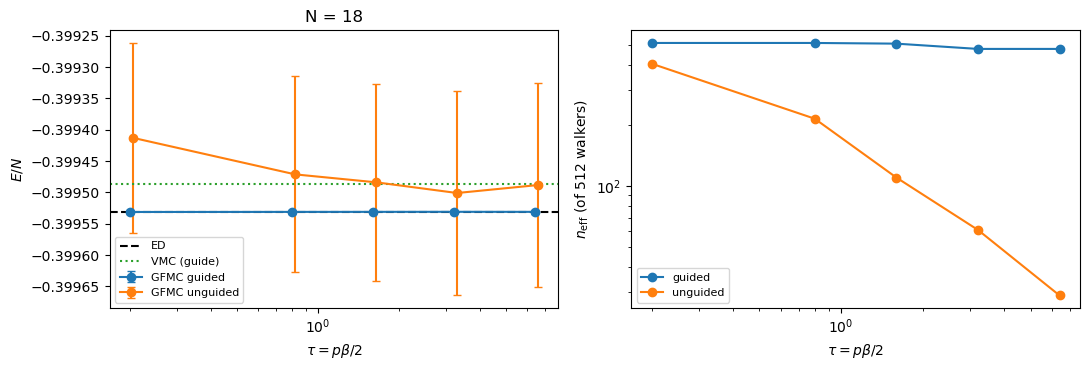

In [9]:
def plot_results(results, N, ref=None, vmc=None):
    fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
    p_array = [2, 8, 16, 32, 64]
    tau = np.array(p_array) * 0.2 / 2           # step_size = 0.2
    for k, (name, res) in enumerate(results.items()):
        e = np.array([res[p][0] for p in p_array]); de = np.array([res[p][1] for p in p_array])
        ne = np.array([res[p][2] for p in p_array])
        ax[0].errorbar(tau * (1 + 0.03 * k), e, de, marker='o', capsize=3, label=f'GFMC {name}')
        ax[1].semilogy(tau, ne, marker='o', label=name)
    if ref is not None:
        ax[0].axhline(ref, color='k', ls='--', label='ED')
    if vmc is not None:
        ax[0].axhline(vmc, color='tab:green', ls=':', label='VMC (guide)')
    ax[0].set_xscale('log'); ax[1].set_xscale('log')
    ax[0].set_xlabel(r'$\tau = p\beta/2$'); ax[1].set_xlabel(r'$\tau = p\beta/2$')
    ax[0].set_ylabel('$E/N$'); ax[1].set_ylabel(r'$n_\mathrm{eff}$ (of %d walkers)' % 512)
    ax[0].legend(fontsize=8); ax[1].legend(fontsize=8)
    ax[0].set_title(f'N = {N}'); plt.tight_layout(); plt.show()


plot_results(res18, h18.N, ref=E0 / h18.N, vmc=E_vmc18 / h18.N)

With the trained guide, GFMC reproduces the exact energy to about $10^{-6}$ per site in every window. Without a
guide the energy has much larger error bars since the effective sample size drops significantly with $\tau$. This is not the case for the guided run.

## 6. A larger lattice: $N=108$

On the $6\times6$ lattice we train a new guide and compare GFMC with and
without it. There is no exact result here, but both runs should give the same energy.

In [10]:
guide108 = ClusterCPS([dict(clusters=stars108, symmetries=D6, parity=True)])   # uniform start
guide108, hist108 = train_with_netket(
    h108, guide108, n_iter=150, learning_rate=0.05, n_samples=1024,
    sr=True, qgt=nk.optimizer.qgt.QGTJacobianDense, diag_shift=1e-2, seed=1, return_history=True)
E_vmc108 = float(np.mean(hist108[-20:]))
print(f'VMC E/N = {E_vmc108 / h108.N:.6f} (mean of last 20 iterations)')

VMC E/N = -0.390482 (mean of last 20 iterations)


[gfmc] - [run_warmup 1/4] - step=0.025, 250 steps @ 25.3 it/s — avg_log_weight = 42.129234


[gfmc] - [run_warmup 2/4] - step=0.05, 250 steps @ 18.9 it/s — avg_log_weight = 42.220070


[gfmc] - [run_warmup 3/4] - step=0.1, 250 steps @ 14.6 it/s — avg_log_weight = 42.213249


[gfmc] - [run_warmup 4/4] - step=0.2, 250 steps @ 10.8 it/s — avg_log_weight = 42.220718


[gfmc] - [run_gfmc] - step: 100/2000, 7.9 it/s, N_config = 503/512 (98.2%) Energy[p]: {2: -42.22106918917684, 8: -42.22139521399519, 16: -42.221003002507295, 32: -42.22150407849397, 64: -42.22158762035113}


...

[gfmc] - [run_gfmc] - step: 1700/2000, 38.3 it/s, N_config = 359/512 (70.1%) Energy[p]: {2: -42.052300288810066, 8: -42.183569952481754, 16: -42.193429235410264, 32: -42.21348913412599, 64: -42.5122798846273}


[gfmc] - [run_gfmc] - step: 1800/2000, 38.8 it/s, N_config = 384/512 (75.0%) Energy[p]: {2: -42.06552365484873, 8: -42.203816765608494, 16: -42.198954302403365, 32: -42.21407324307095, 64: -42.51188465395976}


[gfmc] - [run_gfmc] - step: 1900/2000, 38.1 it/s, N_config = 366/512 (71.5%) Energy[p]: {2: -42.05423284836801, 8: -42.191689672431195, 16: -42.178738400358085, 32: -42.20649839662671, 64: -42.50742806475729}


[gfmc] - [run_gfmc] - step: 2000/2000, 38.4 it/s, N_config = 387/512 (75.6%) Energy[p]: {2: -42.0615187610156, 8: -42.19504489448308, 16: -42.183366023724936, 32: -42.20550820538956, 64: -42.5045634558034}


[estimators] - [statistics] - 10 branching steps (+22 lineage-only)
[estimators] - [statistics] - N_walkers: 512
[estimators] - [statistics] - step_size: 0.2
[estimators] - [statistics] - lam: not used
[estimators] - [statistics] - avg_log_weight: 41.958611
[estimators] - [statistics] - unique (pre): 370.6 ± 8.5  (72.4%)
[estimators] - [statistics] - unique (post): 368.4 ± 6.5  (72.0%)
[estimators] - [statistics] - H_diag: min=-17.0000, max=1.0000  (observed max over the 10 health steps)
[estimators] - [statistics] - escape rate: min=26.5000, max=35.5000
[estimators] - [statistics] - hops per branching step (Gamma*step_size): mean=6.351, max=7.100
[estimators] - [statistics] - escape rate Gamma: mean=31.757, min=26.500, max=35.500
[estimators] - [statistics] - hold time (a draw of 1/Gamma, not hops per step): mean=0.0315, max=0.3615
[estimators] - [statistics] - changed (per-index): 100.0% avg over 10 steps
[estimators] - [statistics] - overlap (pop):       0.1% avg over 10 steps
[esti

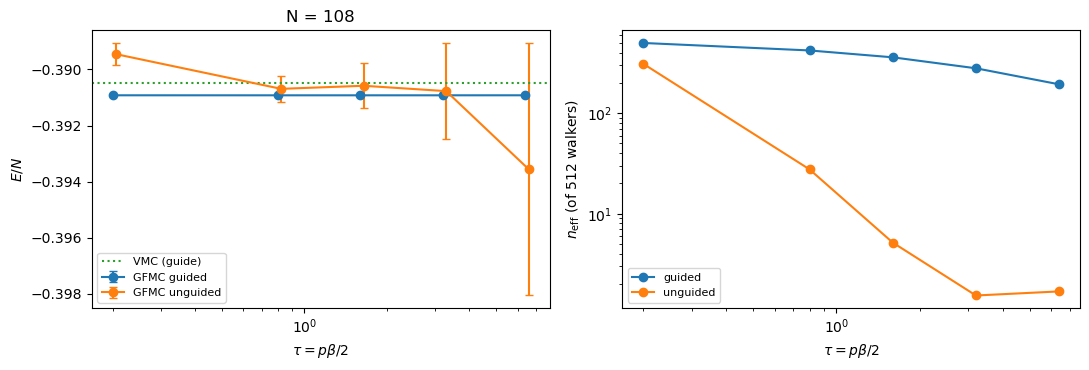

In [11]:
res108 = {'guided':   gfmc(h108, guide108, 2000, seed=30, verbosity=8, number_of_outputs=20),
          'unguided': gfmc(h108, None,     2000, seed=40, verbosity=8, number_of_outputs=20)}
plot_results(res108, h108.N, vmc=E_vmc108 / h108.N)

Both GFMC runs give the same energy, but the unguided run has larger fluctuations due to a sample collapse. We see that GFMC clearly lowers the variational energy of our ansatz wavefunction (dotted green).

In [12]:
os.remove(GUIDE_FILE)          # comment out to keep the trained guide